# 12.1  -  Action Trigger: Ensemble Hindcast

Return period analysis using ensemble forecast hindcast results (2006-2024).
The trigger fires per region when the **ensemble probability** of exceeding a damage threshold
meets a required probability threshold. Two dimensions are swept:
**required probability** (50–95 %) and **damage threshold** (per region).
The composite trigger fires when any region meets its criterion.
Target: composite RP ≈ 3 yr (6 seasons in 19 years).

In [14]:
import io, sys
from itertools import product as iproduct
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ocha_stratus as stratus
from IPython.display import display
from src.constants import CHD_GREEN

plt.rcParams.update({"font.family": "sans-serif"})

In [15]:
CONTAINER    = "projects"
STAGE        = "dev"
PREFIX       = "pa-aa-phl-storms/processed/"
RECORD_YEARS = 19
TARGET_RP    = 3
TARGET_SEAS  = round(RECORD_YEARS / TARGET_RP)   # = 6

TARGET_REGIONS = ["Region II", "Region III", "Region V", "Region VIII"]
PROB_ORDER     = [0.95, 0.80, 0.70, 0.60, 0.50]

REGION_COLORS = {
    "Region II":   "#1565C0",
    "Region III":  "#E65100",
    "Region V":    "#6A1B9A",
    "Region VIII": "#B71C1C",
}

def _fmt_rp(v):
    return "∞" if v >= 99 else f"{v:.1f}"

def _thr_label(d):
    return f"{d // 1000}k" if d % 1000 == 0 else f"{d / 1000:.1f}k"

TBL_STYLES = [
    {"selector": "caption", "props": "text-align:left;padding:4px 0 10px 0;"},
    {"selector": "th",      "props": "background:#f5f5f5;padding:7px 12px;"
                                     "font-weight:600;text-align:center;"},
    {"selector": "td",      "props": "padding:6px 12px;text-align:center;"},
]

In [16]:
ENS_BLOB = (
    PREFIX + "all_storms_hindcast_results/"
    "ensemble_500increments_corrected/all_ensemble_500increment_corrected_raw.csv"
)

raw = stratus.load_blob_data(ENS_BLOB, stage=STAGE, container_name=CONTAINER)
ens_df = pd.read_csv(io.BytesIO(raw))

if "region" in ens_df.columns and "Region" not in ens_df.columns:
    ens_df.rename(columns={"region": "Region"}, inplace=True)
ens_df["storm"] = ens_df["storm"].str.upper()

# Threshold columns are string integers (houses damaged); values = ensemble probability (0–1)
THR_COLS      = [c for c in ens_df.columns if str(c).isdigit()]
dmg_thresholds = [int(c) for c in THR_COLS]
dmg_labels     = [f"{d // 1000}k" for d in dmg_thresholds]
prob_labels    = [f"{p:.0%}" for p in PROB_ORDER]

N_STORMS = ens_df[["storm", "year"]].drop_duplicates().shape[0]

print(f"{N_STORMS} storms  |  {len(THR_COLS)} damage thresholds  |  years: "
      f"{int(ens_df['year'].min())}–{int(ens_df['year'].max())}")
print(f"Prob thresholds swept : {prob_labels}")
print(f"Dmg thresholds (first 5): {dmg_labels[:5]}  …  {dmg_labels[-1]}")
print(f"Ensemble prob value range: {ens_df[THR_COLS].values.min():.2f}"
      f" – {ens_df[THR_COLS].values.max():.2f}")

79 storms  |  80 damage thresholds  |  years: 2006–2024
Prob thresholds swept : ['95%', '80%', '70%', '60%', '50%']
Dmg thresholds (first 5): ['0k', '1k', '1k', '2k', '2k']  …  40k
Ensemble prob value range: 0.00 – 1.00


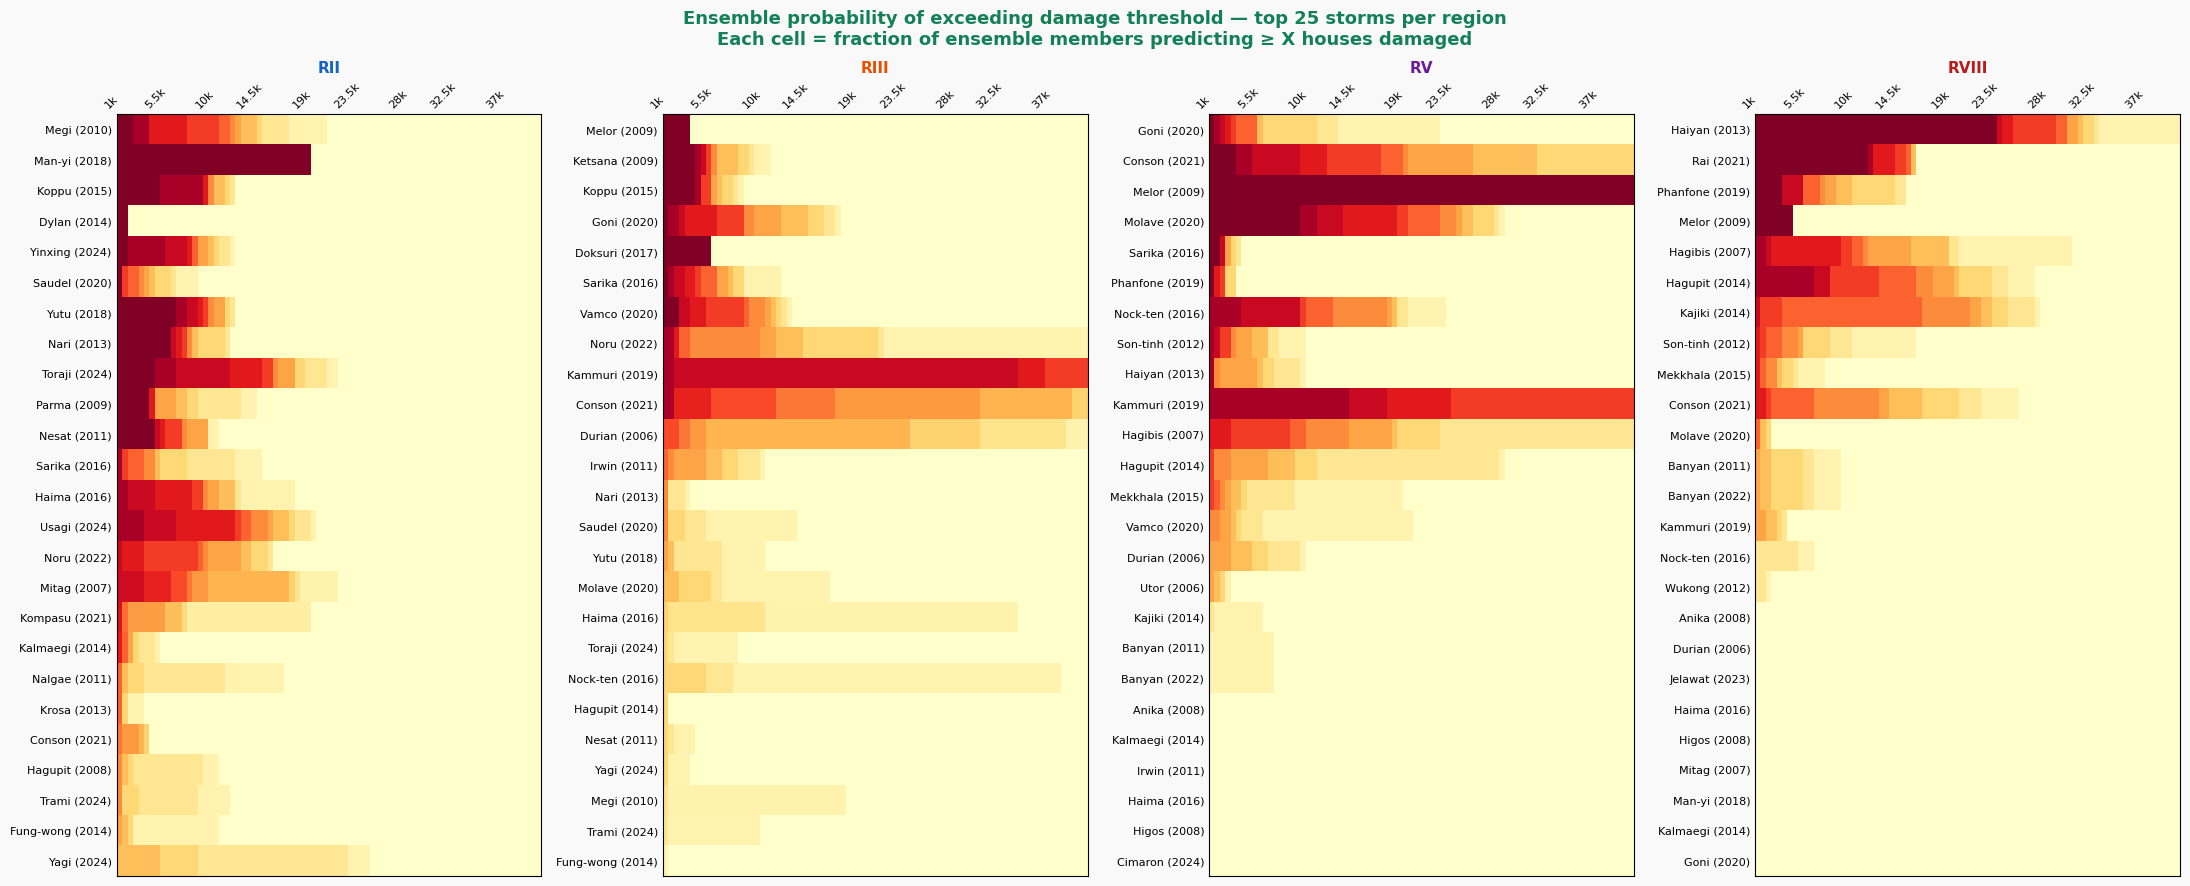

In [17]:
# ── Ensemble probability heatmaps: top 25 storms × damage threshold per region ─
# Values = fraction of ensemble members predicting >= that damage threshold.
# Top 25 storms by max probability across all thresholds, highest first.

TOP_N     = 25
SHOW_THRS = THR_COLS[1:]  # start at 1k (skip 500)

tick_step = max(1, len(SHOW_THRS) // 8)
tick_idxs = list(range(0, len(SHOW_THRS), tick_step))
tick_labs = [_thr_label(int(SHOW_THRS[i])) for i in tick_idxs]

fig, axes = plt.subplots(1, 4, figsize=(22, TOP_N * 0.28 + 2))
fig.patch.set_facecolor("#f9f9f9")
fig.suptitle(
    f"Ensemble probability of exceeding damage threshold — top {TOP_N} storms per region\n"
    "Each cell = fraction of ensemble members predicting ≥ X houses damaged",
    fontsize=13, fontweight="bold", color=CHD_GREEN,
)

for ax, region in zip(axes, TARGET_REGIONS):
    ax.set_facecolor("#f9f9f9")
    sub = ens_df[ens_df["Region"] == region].copy()
    sub["label"] = sub["storm"].str.capitalize() + " (" + sub["year"].astype(int).astype(str) + ")"

    pivot = (
        sub[["label"] + SHOW_THRS]
        .set_index("label")
        .astype(float)
    )
    pivot = (
        pivot.loc[pivot.max(axis=1).sort_values(ascending=False).index]
        .head(TOP_N)
    )

    ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=1, interpolation="nearest")

    ax.set_xticks(tick_idxs)
    ax.set_xticklabels(tick_labs, fontsize=8, rotation=45, ha="right")
    ax.set_yticks(range(len(pivot)))
    ax.set_yticklabels(pivot.index, fontsize=8)
    ax.tick_params(axis="x", labeltop=True, labelbottom=False, length=0)
    ax.tick_params(axis="y", length=0)
    ax.set_title(
        region.replace("Region ", "R"), fontsize=11, fontweight="bold",
        color=REGION_COLORS[region],
    )

plt.tight_layout()
plt.show()

In [18]:
# Build (prob × dmg) RP grids per region.
# A storm triggers for (region, prob, dmg) when its ensemble probability
# of exceeding dmg houses >= required prob.
trigger_keys = {}
region_rp    = {}

for region in TARGET_REGIONS:
    sub    = ens_df[ens_df["Region"] == region]
    rp_arr = np.full((len(PROB_ORDER), len(dmg_thresholds)), 99.0)

    for pi, prob in enumerate(PROB_ORDER):
        for di, (col, dmg) in enumerate(zip(THR_COLS, dmg_thresholds)):
            triggered = sub[sub[col] >= prob]
            seasons   = triggered["year"].nunique()
            rp_arr[pi, di] = round(RECORD_YEARS / seasons, 1) if seasons > 0 else 99.0
            trigger_keys[(region, prob, dmg)] = frozenset(
                zip(triggered["storm"], triggered["year"].astype(int))
            )

    region_rp[region] = rp_arr

print("Grids built.")
# Show the RP at prob=0.50 (most liberal) to check plausible range per region
for region in TARGET_REGIONS:
    rp_row = region_rp[region][PROB_ORDER.index(0.50), :]
    target_idx = int(np.argmin(np.abs(rp_row - TARGET_RP)))
    print(f"  {region}: nearest RP {TARGET_RP}yr at prob≥50%"
          f" → {dmg_labels[target_idx]} (RP {_fmt_rp(rp_row[target_idx])} yr)")

Grids built.
  Region II: nearest RP 3yr at prob≥50% → 8k (RP 3.2 yr)
  Region III: nearest RP 3yr at prob≥50% → 5k (RP 3.2 yr)
  Region V: nearest RP 3yr at prob≥50% → 3k (RP 3.2 yr)
  Region VIII: nearest RP 3yr at prob≥50% → 4k (RP 3.2 yr)


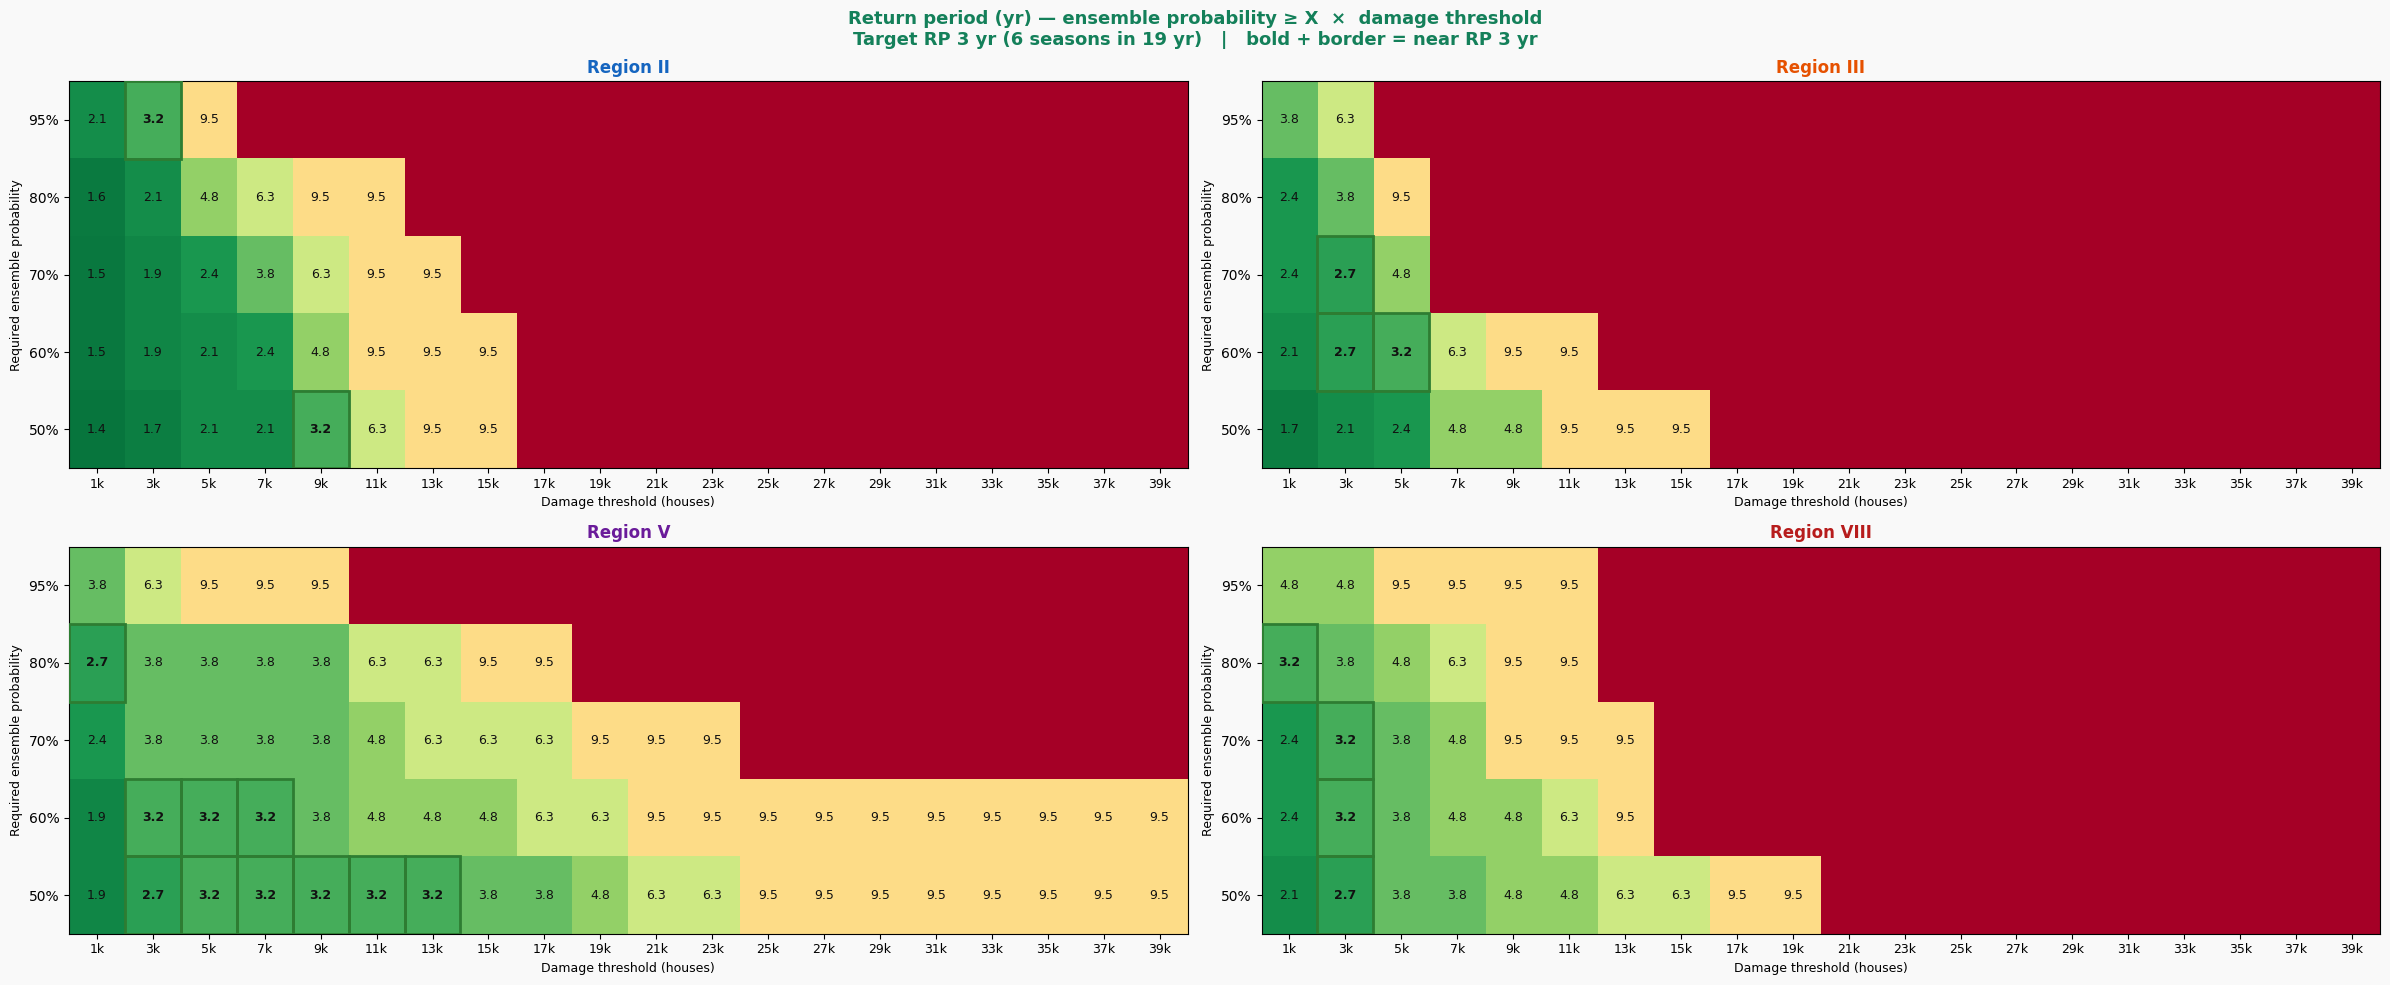

In [19]:
# ── Per-region RP heatmaps: required probability × damage threshold ────────────
# Show every 4th threshold starting at 1k (1k, 3k, 5k, …); no colorbar.
DISP_STEP   = 4
disp_idxs   = list(range(1, len(dmg_thresholds), DISP_STEP))  # start at 1k
disp_labels = [_thr_label(dmg_thresholds[i]) for i in disp_idxs]

fig, axes = plt.subplots(2, 2, figsize=(24, 10))
axes = axes.flatten()
fig.patch.set_facecolor("#f9f9f9")
fig.suptitle(
    f"Return period (yr) — ensemble probability ≥ X  ×  damage threshold\n"
    f"Target RP {TARGET_RP} yr ({TARGET_SEAS} seasons in {RECORD_YEARS} yr)"
    f"   |   bold + border = near RP {TARGET_RP} yr",
    fontsize=13, fontweight="bold", color=CHD_GREEN,
)

for ai, region in enumerate(TARGET_REGIONS):
    ax        = axes[ai]
    ax.set_facecolor("#f9f9f9")
    vals_full = region_rp[region]
    vals      = vals_full[:, disp_idxs]
    disp      = np.clip(vals, 0, 20)

    im = ax.imshow(disp, aspect="auto", cmap="RdYlGn_r", vmin=1, vmax=15)

    for r in range(len(PROB_ORDER)):
        for c in range(len(disp_idxs)):
            v         = vals[r, c]
            at_target = abs(v - TARGET_RP) < 0.4
            if v >= 15:
                continue
            fc = "white" if disp[r, c] > 10 else "#111"
            ax.text(
                c, r, _fmt_rp(v),
                ha="center", va="center", fontsize=9, color=fc,
                fontweight="bold" if at_target else "normal",
            )
            if at_target:
                ax.add_patch(plt.Rectangle(
                    (c - 0.5, r - 0.5), 1, 1,
                    fill=False, edgecolor="#2e7d32", linewidth=2, zorder=4,
                ))

    ax.set_xticks(range(len(disp_idxs)))
    ax.set_xticklabels(disp_labels, fontsize=9, rotation=0, ha="center")
    ax.set_yticks(range(len(PROB_ORDER)))
    ax.set_yticklabels(prob_labels, fontsize=10)
    ax.set_xlabel("Damage threshold (houses)", fontsize=9)
    ax.set_ylabel("Required ensemble probability", fontsize=9)
    ax.set_title(region, fontsize=12, fontweight="bold", color=REGION_COLORS[region])

plt.tight_layout()
plt.show()